# 04 · Features, PCA, regimes and position sizing

Notebook 03 is the **baseline**: 13 features, sign-only positions. This notebook extends it and asks whether each extension helps, using the same walk-forward, ATOMS selection and purged validation:

| Section | Question |
|---|---|
| 1. Regimes, fixed | Does the HMM find market regimes once the intraday volatility cycle is removed? |
| 2. Feature catalogue | ~60 causal features in 11 groups |
| 3. Screening | Which features carry information, judged on 2023 only, with a multiple-testing bar? |
| 4. PCA | How much of the feature set is redundant, and does variance equal signal? |
| 5. Time of day | Is the *direction* of returns predictable by hour, or only volatility? |
| 6. Walk-forward v2 | Does ATOMS with the extended features beat the baseline? |
| 7. Is the edge real? | What survives a one-minute execution delay? |
| 8. Position sizing | Sign vs volatility-targeted vs forecast-proportional, compared at equal risk |

### Leakage rules added in this notebook

| Rule | How |
|---|---|
| Features use only past and current bars | Tested directly: deleting all future bars changes no feature value |
| The HMM's parameters and its time-of-day profile come from the design period | Fitted before `REPORT_FROM`, then frozen and forward-filtered |
| An hourly regime probability is used only after the hour has closed | `regimes.lagged` moves each value to the end of its hour |
| PCA does not see validation or test rows | It runs inside each candidate's pipeline, so it is refitted on that candidate's training rows every period |
| Feature screening and the time-of-day profile use the design period only | Both computed on rows before `REPORT_FROM` |

## Settings

In [1]:
SYMBOL = "BTCUSDT"
DATA_DIR = None
HORIZON = 1
REPORT_FROM = "2024-01-01"

# walk-forward (same as notebook 03 unless changed)
PERIOD = "W-SUN"; WINDOWS = [1, 4, 16, 64, 0]; GBT_MAX_WINDOW = 16
MAX_LOOKBACK = 64; MIN_HISTORY = 4; FH_SHORT = 4
BLOCK_MIN, VAL_FRAC, PURGE_MIN, EMBARGO_MIN = 360, 0.20, 60, 15
SEEDS = [0]; ATOMS_DELTA = 0.1; ATOMS_M = None

# features: "all" = every feature; "screened" = only those clearing the Bonferroni bar on the design period
FEATURE_SET = "all"
USE_REGIME_FEATURES = True
USE_SPECTRAL = True

MODEL_SETTINGS = [
    {"kind": "enet", "alpha": 0.001, "l1_ratio": 0.5},
    {"kind": "enet", "alpha": 0.01,  "l1_ratio": 0.5},
    {"kind": "enet", "alpha": 0.1,   "l1_ratio": 0.5},
    {"kind": "enet", "alpha": 0.01,  "l1_ratio": 0.5, "pca": 0.95},   # PCA inside the candidate
    {"kind": "gbt",  "depth": 2, "lr": 0.05, "n_iter": 150, "min_leaf": 1000},
    {"kind": "gbt",  "depth": 3, "lr": 0.05, "n_iter": 150, "min_leaf": 1000},
]

# sizing and realism
VOL_TARGET = 0.40; LEVERAGE_CAP = 2.0       # volatility-targeted sizing
BAND = 0.5                                 # no-trade band for proportional sizing
DELAYS = [0, 1, 2, 5]                      # execution delay in minutes
EQUAL_RISK = 0.20                          # all equity curves shown at this annual volatility
RERUN = False

In [2]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from btc import features_full, splits, models, regimes, diagnostics, sizing, walkforward, plotting
plotting.use_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

DATA = Path(DATA_DIR) if DATA_DIR else ROOT / "data"
PROC = DATA / "processed"
REPORT_FROM = pd.Timestamp(REPORT_FROM, tz="UTC")
m1 = pd.read_parquet(PROC / f"{SYMBOL}-1m.parquet")

## 1. Regimes, fixed

In notebook 03 the HMM was fitted on raw hourly volatility. BTC's volatility has a strong daily cycle (notebook 02), so a two-state model splits **US hours vs Asian hours**: roughly half of all hours "stormy", with stays of half a day. That is the clock, not the market.

The fix, both steps causal and estimated on the design period only:
1. subtract the average log-volatility of each UTC hour;
2. average the result over a **trailing** 24 hours.

The table compares the two versions. A real regime model should spend a minority of time in the stormy state and stay there for days, not hours.

In [3]:
def describe(h, model):
    p = regimes.regime_series(model, h)
    hi = int(np.argmax(model.means_[:, 1])); lo = 1 - hi
    return {"stormy share of hours (%)": 100 * (p > 0.5).mean(),
            "expected stay, calm (h)": 1 / (1 - model.transmat_[lo, lo]),
            "expected stay, stormy (h)": 1 / (1 - model.transmat_[hi, hi])}, p

h_old = regimes.hourly_inputs(m1)
h_new = regimes.hourly_inputs(m1, design_end=REPORT_FROM, smooth_hours=24)
hmm_old = regimes.fit_hmm(h_old[h_old.index < REPORT_FROM])
hmm_new = regimes.fit_hmm(h_new[h_new.index < REPORT_FROM])
d_old, _ = describe(h_old, hmm_old)
d_new, p_high = describe(h_new, hmm_new)
regime = (p_high > 0.5).rename("stormy")
pd.DataFrame({"raw hourly volatility (notebook 03)": d_old, "deseasonalised + 24h trailing (this notebook)": d_new}).style.format("{:.1f}")

,raw hourly volatility (notebook 03),deseasonalised + 24h trailing (this notebook)
stormy share of hours (%),52.2,74.5
"expected stay, calm (h)",12.3,42.4
"expected stay, stormy (h)",8.5,70.2


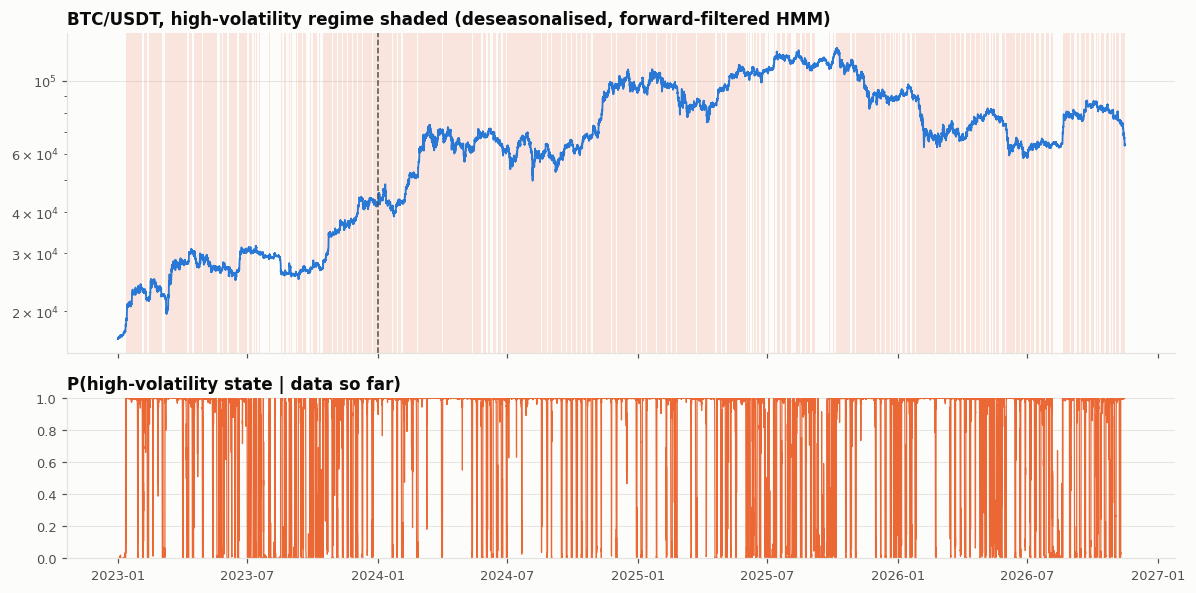

In [4]:
def shade_regimes(ax, reg=regime, color=plotting.ORANGE):
    r = reg.astype(int); e = r.diff().fillna(r.iloc[0])
    starts, ends = r.index[e == 1], r.index[e == -1]
    if r.iloc[-1] == 1: ends = ends.append(pd.DatetimeIndex([r.index[-1]]))
    for s, t in zip(starts, ends): ax.axvspan(s, t, color=color, alpha=0.15, lw=0)

fig, (a, b) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
px = m1["close"].resample("1h").last()
a.plot(px.index, px, color=plotting.BLUE, lw=1.2); shade_regimes(a); a.set_yscale("log")
a.axvline(REPORT_FROM, color=plotting.MUTED, ls="--", lw=1)
a.set_title("BTC/USDT, high-volatility regime shaded (deseasonalised, forward-filtered HMM)")
b.plot(p_high.index, p_high, color=plotting.ORANGE, lw=0.8); b.set_ylim(0, 1); b.set_title("P(high-volatility state | data so far)")
plt.tight_layout(); plt.show()

## 2. Feature catalogue

Every feature at minute *i* uses bars up to and including *i*. The regime group uses the HMM probability **after its hour has closed** (`regimes.lagged`).

The time group's three harmonics matter: one sine/cosine pair can only express a single smooth daily wave. The 12-hour and 8-hour harmonics let a model represent "good at 14:00, bad at 16:00", and the 8-hour cycle lines up with the 00:00 / 08:00 / 16:00 UTC funding times of perpetual futures.

Signal-processing features that are **not** included, on purpose: the Hilbert transform and singular spectrum analysis are computed over a window, and their value at the window's last point is the least reliable one because of edge effects. That last point is exactly the one a strategy would trade on.

In [5]:
p_storm = regimes.lagged(p_high) if USE_REGIME_FEATURES else None
F, groups = features_full.build_full(m1, horizon=HORIZON, p_storm=p_storm, spectral=USE_SPECTRAL)
all_cols = [c for v in groups.values() for c in v]
print(f"{len(F):,} usable minutes, {len(all_cols)} features")
pd.DataFrame({"features": {k: len(v) for k, v in groups.items()},
              "what they measure": {k: features_full.GROUP_DOC[k] for k in groups},
              "columns": {k: ", ".join(v) for k, v in groups.items()}})

2,034,158 usable minutes, 64 features


,features,what they measure,columns
momentum,12,log returns over the last 1 minute to 1 day,"ret_1, ret_2, ret_3, ret_5, ret_10, ret_15, re..."
volatility,9,"realised and high-low (Parkinson) volatility, ...","rv_5, rv_15, rv_60, rv_240, rv_1440, pk_15, pk..."
scaled,4,returns divided by recent volatility (how unus...,"zret_5, zret_15, zret_60, zret_240"
location,5,distance from moving averages and position in ...,"dist_ma_60, dist_ma_240, dist_ma_1440, range_p..."
moments,2,rolling skewness and kurtosis of 1-minute returns,"skew_240, kurt_240"
dependence,2,rolling lag-1 autocorrelation and 5-minute var...,"ac1_240, vr5_240"
activity,5,"volume, trade count and average trade size vs ...","vol_z, vol_z_60, trades_z, size_z, vol_mom_15_240"
order_flow,8,"taker-buy imbalance, volume-weighted imbalance...","imb_1, imb_5, imb_15, imb_60, vw_imb_15, vw_im..."
time,9,"hour of day (3 harmonics: 24h, 12h, 8h cycles)...","hour_sin_1, hour_cos_1, hour_sin_2, hour_cos_2..."
spectral,2,spectral entropy and low-frequency power share...,"spec_entropy_64, low_band_64"


In [6]:
# causality check: rebuild using data only up to a cut-off; no feature value before the cut-off may change
cut = F.index[len(F) // 2]
F_cut, _ = features_full.build_full(m1[m1.index <= cut], horizon=HORIZON,
                                    p_storm=None if p_storm is None else p_storm[p_storm.index <= cut], spectral=USE_SPECTRAL)
common = F_cut.index.intersection(F.index)
common = common[common <= cut - pd.Timedelta(minutes=HORIZON)]
diff = (F.loc[common, all_cols].astype(float) - F_cut.loc[common, all_cols].astype(float)).abs().max().max()
print(f"Largest change in any feature when all data after {cut} is deleted: {diff:.2e}  (0 = no look-ahead)")

Largest change in any feature when all data after 2024-12-08 16:40:00+00:00 is deleted: 0.00e+00  (0 = no look-ahead)


## 3. Screening on the design period

For each feature: the **information coefficient (IC)**, the rank correlation between the feature and the next return, computed **per day** on 2023 only. The t-statistic is the mean daily IC over its standard error across days, so serial dependence inside a day does not inflate it.

With ~60 features tested, a few will look significant by chance. The **Bonferroni bar** raises the threshold to |t| > ~3.2. "Months same sign" asks whether the effect is stable or flips around.

Constant within each day, so a daily IC is undefined (judged in section 5 instead): weekend
Bonferroni bar: |t| > 3.36;  31 of 63 features pass


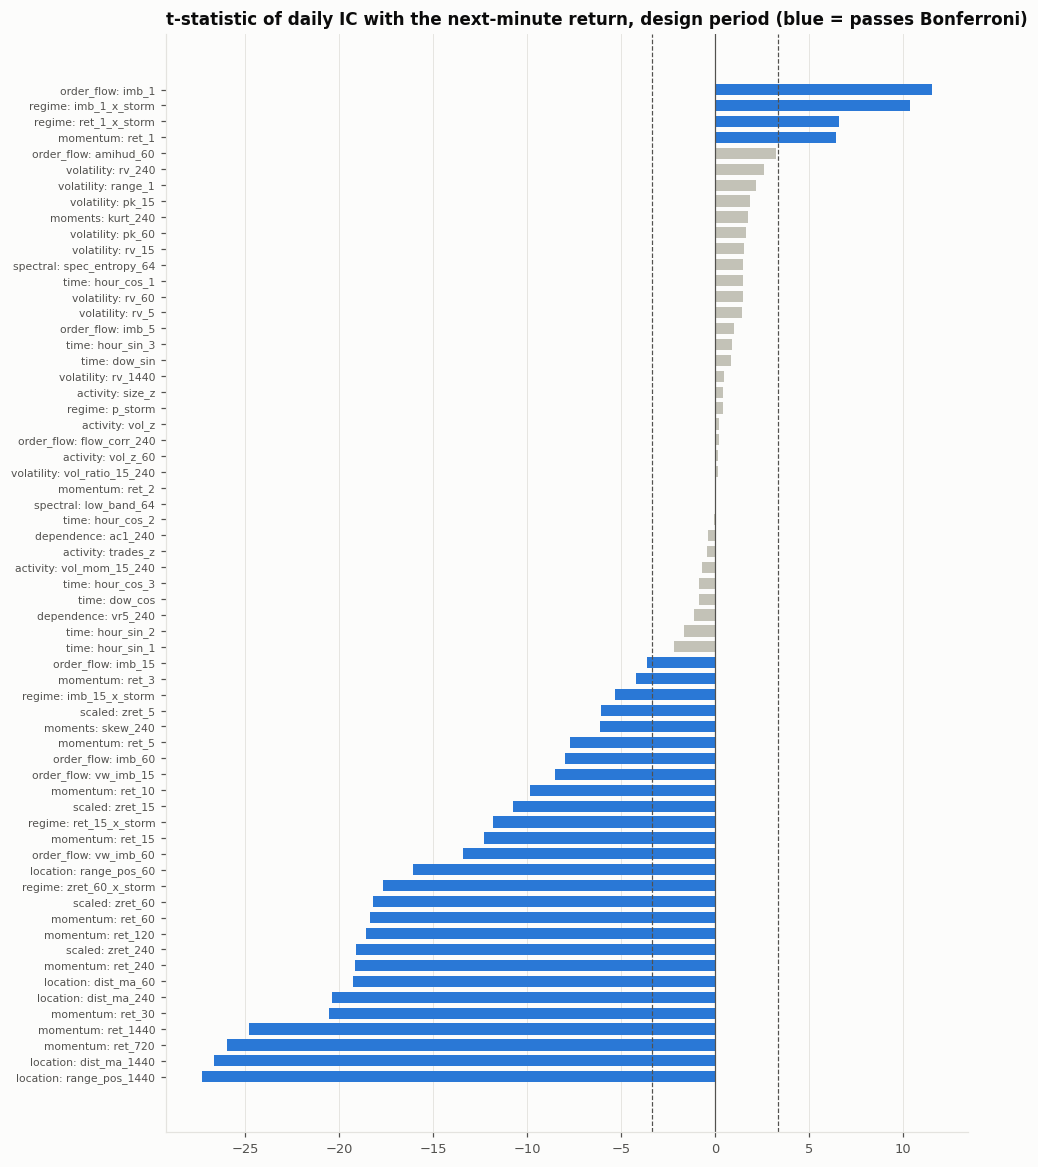

,group,mean_ic,t_stat,months_same_sign,passes_bonferroni
range_pos_1440,location,-0.0417,-27.28,100%,True
dist_ma_1440,location,-0.0372,-26.64,100%,True
ret_720,momentum,-0.0333,-25.96,100%,True
ret_1440,momentum,-0.0345,-24.82,100%,True
ret_30,momentum,-0.0297,-20.54,100%,True
dist_ma_240,location,-0.0323,-20.37,100%,True
dist_ma_60,location,-0.0301,-19.24,92%,True
ret_240,momentum,-0.0279,-19.18,100%,True
zret_240,scaled,-0.0270,-19.11,100%,True
ret_120,momentum,-0.0284,-18.60,100%,True


In [7]:
design = F[F.index < REPORT_FROM]
scr = diagnostics.screen(design, groups)
undefined = list(scr.index[scr.t_stat.isna()])
if undefined: print("Constant within each day, so a daily IC is undefined (judged in section 5 instead):", ", ".join(undefined))
scr = scr.dropna(subset=["t_stat"])
print(f"Bonferroni bar: |t| > {scr.attrs['bar']:.2f};  {int(scr.passes_bonferroni.sum())} of {len(scr)} features pass")

fig, ax = plt.subplots(figsize=(9, max(4, 0.17 * len(scr))))
s = scr.sort_values("t_stat")
ax.barh([f"{g}: {c}" for c, g in zip(s.index, s.group)], s.t_stat,
        color=[plotting.BLUE if p else "#c3c2b7" for p in s.passes_bonferroni], height=0.7)
for x in (-scr.attrs["bar"], scr.attrs["bar"]): ax.axvline(x, color=plotting.MUTED, ls="--", lw=0.8)
ax.axvline(0, color=plotting.MUTED, lw=0.8); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("t-statistic of daily IC with the next-minute return, design period (blue = passes Bonferroni)")
ax.tick_params(axis="y", labelsize=7); plt.tight_layout(); plt.show()
scr.head(15).style.format({"mean_ic": "{:+.4f}", "t_stat": "{:+.2f}", "months_same_sign": "{:.0%}"})

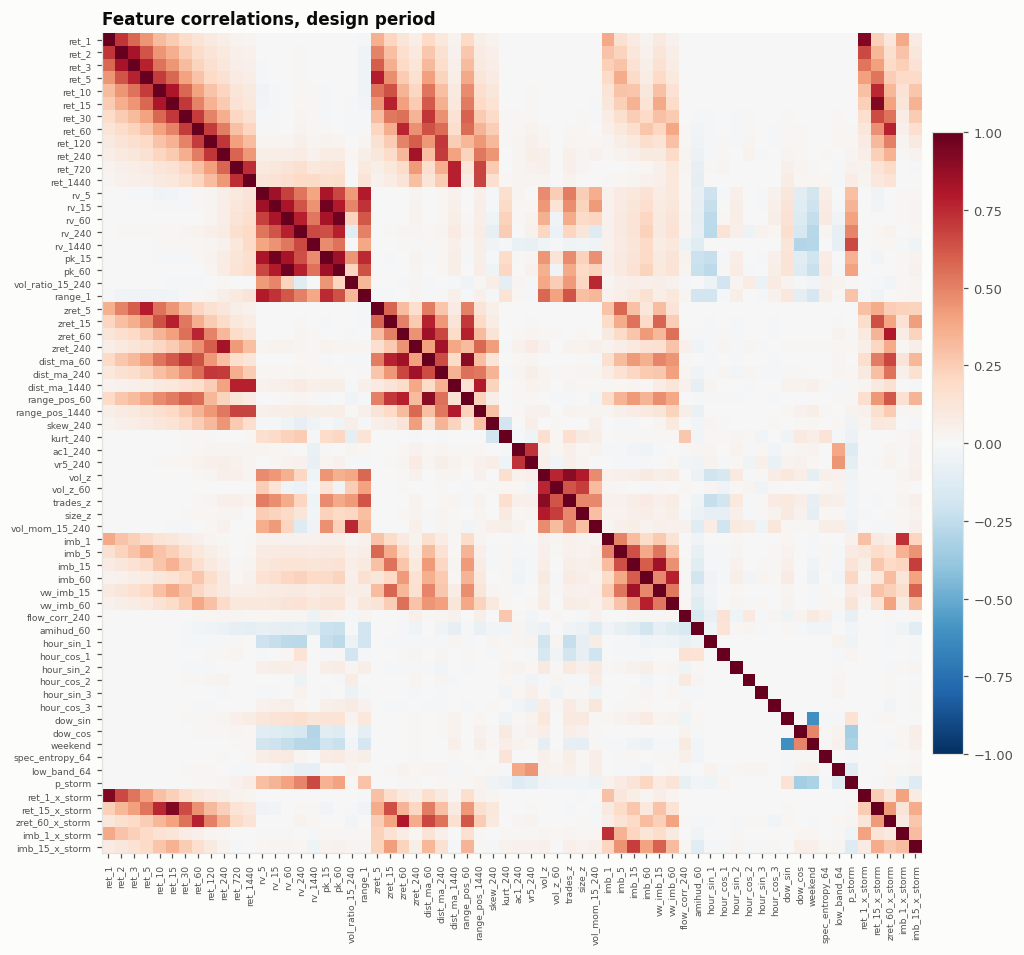

Feature pairs with |correlation| > 0.8: 18 of 2016


In [8]:
C = design[all_cols].corr()
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(C.values, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(C))); ax.set_xticklabels(C.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(C))); ax.set_yticklabels(C.columns, fontsize=6)
ax.set_title("Feature correlations, design period"); fig.colorbar(im, ax=ax, pad=0.01, shrink=0.7); plt.tight_layout(); plt.show()
pairs = C.where(np.triu(np.ones(C.shape, bool), 1)).stack()
print(f"Feature pairs with |correlation| > 0.8: {(pairs.abs() > 0.8).sum()} of {len(pairs)}")

## 4. PCA: redundancy, and why variance is not signal

~60 features is **not** too many for ~2 million rows; the model has plenty of data per parameter. PCA's job here is different: many features are near-duplicates (the volatility measures, the overlapping return windows), and PCA collapses them into a handful of uncorrelated factors.

The catch: PCA ranks directions by how much the *features* vary, not by how well they *predict*. A component that explains 0.5% of feature variance can carry all of the signal, and keeping "95% of variance" can throw it away. The last chart tests this directly.

So PCA enters the strategy as **one more candidate**, an elastic net on PCA factors re-estimated inside every training window, and ATOMS decides whether it earns its place.

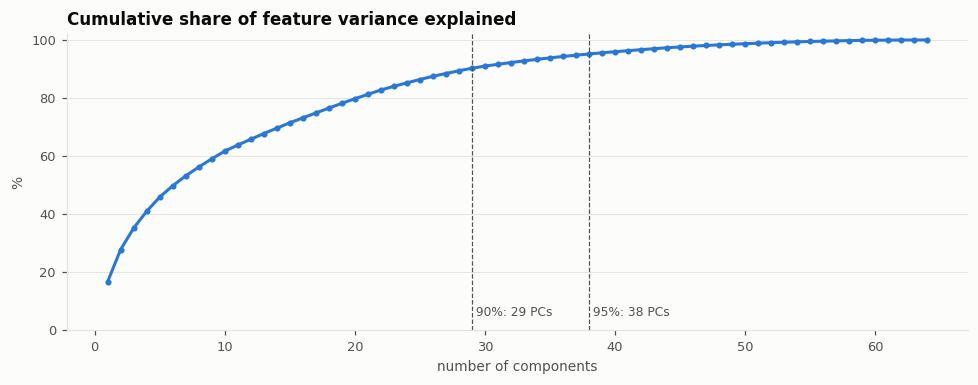

64 features -> 29 components for 90% of variance, 38 for 95%


In [9]:
share, load, to_pc = diagnostics.pca_fit(design[all_cols].to_numpy(dtype="float64"))
cum = np.cumsum(share)
k90, k95 = int(np.searchsorted(cum, 0.90) + 1), int(np.searchsorted(cum, 0.95) + 1)
fig, ax = plt.subplots()
ax.plot(range(1, len(cum) + 1), 100 * cum, color=plotting.BLUE, marker="o", ms=3)
for k, lab in ((k90, "90%"), (k95, "95%")):
    ax.axvline(k, color=plotting.MUTED, ls="--", lw=0.8); ax.text(k, 5, f" {lab}: {k} PCs", fontsize=8, color=plotting.MUTED)
ax.set_ylim(0, 102); ax.set_xlabel("number of components"); ax.set_ylabel("%")
ax.set_title("Cumulative share of feature variance explained"); plt.tight_layout(); plt.show()
print(f"{len(all_cols)} features -> {k90} components for 90% of variance, {k95} for 95%")

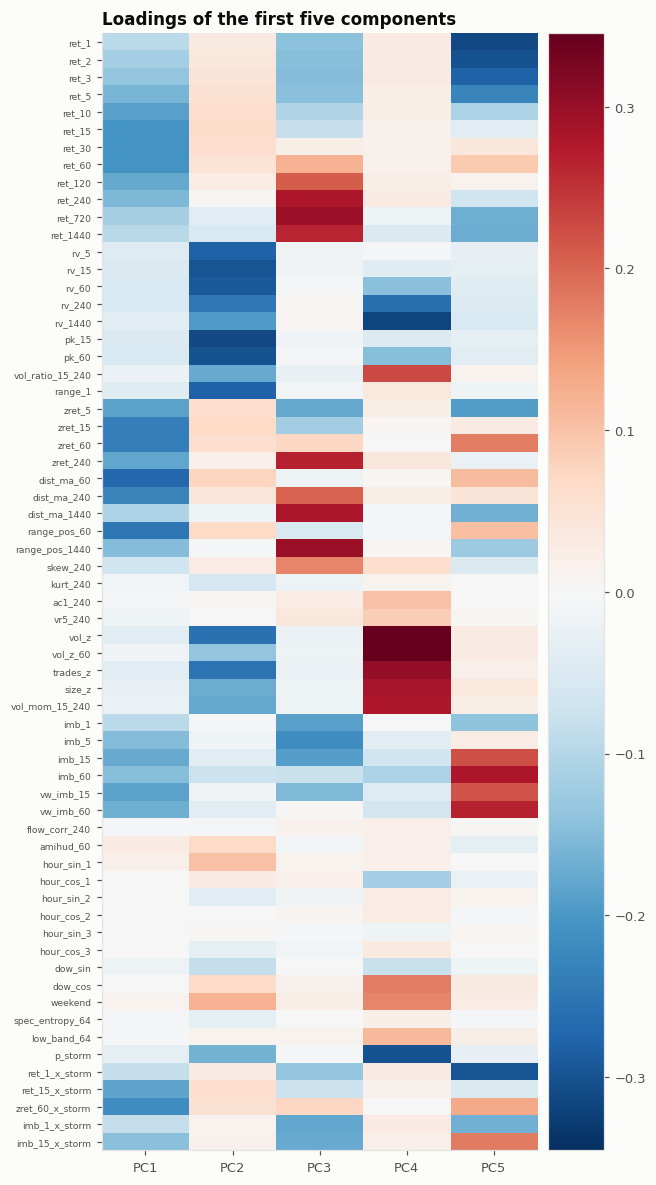

PC1 (16.7% of variance): dist_ma_60 -0.27, range_pos_60 -0.25, zret_60 -0.24, zret_15 -0.24
PC2 (11.1% of variance): pk_15 -0.31, pk_60 -0.30, rv_15 -0.30, rv_60 -0.29
PC3 (7.4% of variance): range_pos_1440 +0.29, ret_720 +0.29, dist_ma_1440 +0.28, ret_240 +0.28
PC4 (5.8% of variance): vol_z_60 +0.35, vol_z +0.34, rv_1440 -0.32, trades_z +0.30
PC5 (4.9% of variance): ret_1 -0.31, ret_2 -0.30, ret_1_x_storm -0.30, ret_3 -0.28


In [10]:
L = pd.DataFrame(load[:, :5], index=all_cols, columns=[f"PC{i}" for i in range(1, 6)])
fig, ax = plt.subplots(figsize=(6, max(4, 0.17 * len(all_cols))))
im = ax.imshow(L.values, aspect="auto", cmap="RdBu_r", vmin=-np.abs(L.values).max(), vmax=np.abs(L.values).max())
ax.set_yticks(range(len(L))); ax.set_yticklabels(L.index, fontsize=6); ax.set_xticks(range(5)); ax.set_xticklabels(L.columns); ax.grid(False)
ax.set_title("Loadings of the first five components"); fig.colorbar(im, ax=ax, pad=0.02); plt.tight_layout(); plt.show()
for c in L.columns:
    top = L[c].abs().sort_values(ascending=False).index[:4]
    print(f"{c} ({100*share[int(c[2:])-1]:.1f}% of variance): " + ", ".join(f"{t} {L.loc[t, c]:+.2f}" for t in top))

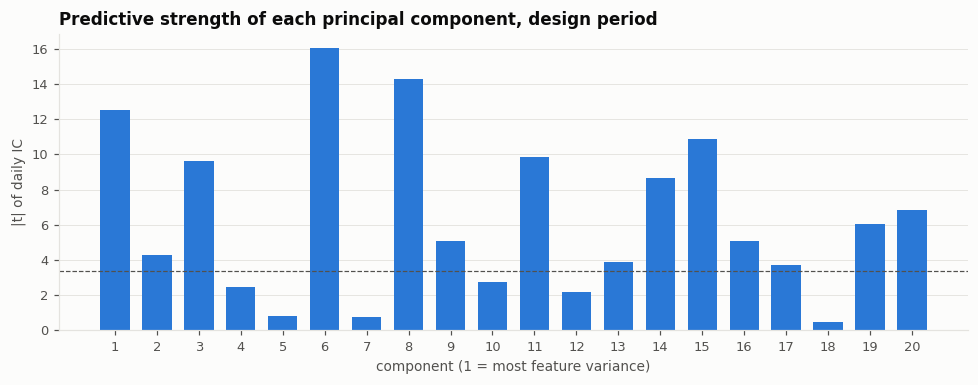

Most predictive component: PC6, |t| = 16.0


In [11]:
pcs = pd.DataFrame(to_pc(design[all_cols].to_numpy(dtype="float64"))[:, :20], index=design.index,
                   columns=[f"PC{i}" for i in range(1, 21)])
pcs["y"] = design["y"]
pc_ic = diagnostics.daily_ic(pcs, list(pcs.columns[:-1]))
t_pc = pc_ic.mean() / (pc_ic.std() / np.sqrt(pc_ic.count()))
fig, ax = plt.subplots()
ax.bar(range(1, 21), t_pc.abs().values, width=0.7, color=plotting.BLUE)
ax.set_xticks(range(1, 21)); ax.set_xlabel("component (1 = most feature variance)"); ax.set_ylabel("|t| of daily IC")
ax.axhline(scr.attrs["bar"], color=plotting.MUTED, ls="--", lw=0.8)
ax.set_title("Predictive strength of each principal component, design period"); plt.tight_layout(); plt.show()
print(f"Most predictive component: PC{int(t_pc.abs().idxmax()[2:])}, |t| = {t_pc.abs().max():.1f}")

## 5. Time of day: volatility or direction?

Notebook 02 showed volatility and volume follow the clock. A "buy at hour X, sell at hour Y" strategy needs something different: the **average return** to depend on the hour, and in the same way every year.

With 24 hours and 276 possible (buy, sell) pairs, some will look good by chance. The honest test: estimate each hour's average return on the design period, then check whether the same hours are good afterwards. A correlation near zero means the hourly pattern in direction is noise.

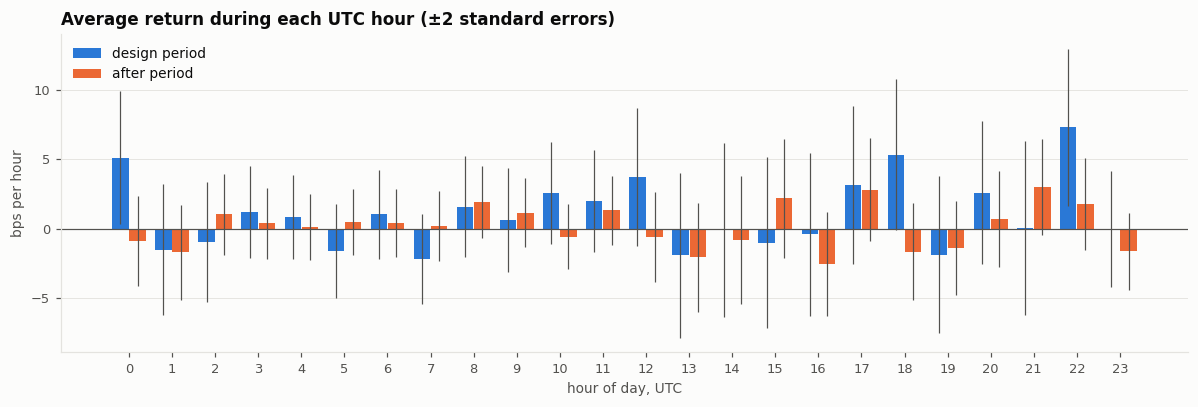

Correlation of hourly average returns, design vs after: +0.18


In [12]:
hp = diagnostics.hour_profile(F, REPORT_FROM)
rho = hp[("mean", "design")].corr(hp[("mean", "after")])
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(24)
for off, per, col in ((-0.2, "design", plotting.BLUE), (0.2, "after", plotting.ORANGE)):
    ax.bar(x + off, 60 * hp[("mean", per)], width=0.38, yerr=2 * 60 * hp[("se", per)], color=col,
           ecolor=plotting.MUTED, error_kw={"lw": 0.8}, label=f"{per} period")
ax.axhline(0, color=plotting.MUTED, lw=0.8); ax.set_xticks(x); ax.legend(loc="upper left")
ax.set_xlabel("hour of day, UTC"); ax.set_ylabel("bps per hour")
ax.set_title("Average return during each UTC hour (±2 standard errors)"); plt.tight_layout(); plt.show()
print(f"Correlation of hourly average returns, design vs after: {rho:+.2f}")

The time-of-day rule is also kept as a **benchmark strategy**: long during hours whose design-period average was positive, short otherwise, fixed from then on.

## 6. Walk-forward v2

Same loop as notebook 03, with the extended feature set and the PCA candidate. Results are cached separately (`wf_v2_*`), and notebook 03's cached results are loaded as the baseline.

This is slower than notebook 03: about four times the features. Expect several hours on the full history. The progress line shows the elapsed time after each period.

In [13]:
feat_cols = all_cols if FEATURE_SET == "all" else list(scr.index[scr.passes_bonferroni])
cands = models.candidate_grid(MODEL_SETTINGS, WINDOWS, GBT_MAX_WINDOW)
print(f"Feature set '{FEATURE_SET}': {len(feat_cols)} features;  {len(cands)} candidates")
runs = {}
for seed in SEEDS:
    f_sel, f_fc = PROC / f"wf_v2_selections_seed{seed}.parquet", PROC / f"wf_v2_forecasts_seed{seed}.parquet"
    if f_sel.exists() and f_fc.exists() and not RERUN:
        runs[seed] = {"selections": pd.read_parquet(f_sel), "forecasts": pd.read_parquet(f_fc)}
        print(f"seed {seed}: loaded cached results"); continue
    frame = splits.split_all(F[feat_cols + ["y", "ret_fwd"]], PERIOD, BLOCK_MIN, VAL_FRAC, PURGE_MIN, EMBARGO_MIN, seed)
    runs[seed] = walkforward.run(frame, cands, min_history=MIN_HISTORY, max_lookback=MAX_LOOKBACK, fh_short=FH_SHORT,
                                 atoms_delta=ATOMS_DELTA, atoms_M=ATOMS_M, seed=seed, feature_cols=feat_cols,
                                 checkpoint_dir=PROC / f"wf_v2_ckpt_seed{seed}")
    runs[seed]["selections"].to_parquet(f_sel); runs[seed]["forecasts"].to_parquet(f_fc)
sel, fc = runs[SEEDS[0]]["selections"], runs[SEEDS[0]]["forecasts"]
base = pd.read_parquet(PROC / f"wf_forecasts_seed{SEEDS[0]}.parquet")   # notebook 03

Feature set 'all': 64 features;  27 candidates


seed 0: loaded cached results


In [14]:
idx = fc.index[fc.index >= REPORT_FROM].intersection(base.index)
rep, b = fc.loc[idx].copy(), base.loc[idx]
r2 = lambda f: 100 * (1 - np.sum((f - rep["y"]) ** 2) / np.sum(rep["y"] ** 2))
cand_cols = [c.label for c in cands]
fixed = {c: r2(rep[c]) for c in cand_cols if c != "zero"}
best_fixed = max(fixed, key=fixed.get)
tab = pd.Series({"ATOMS, v2 features": r2(rep["atoms"]), "ATOMS, baseline (nb 03)": r2(b["atoms"]),
                 "FH-Short, v2": r2(rep["fh_short"]), "FH-Long, v2": r2(rep["fh_long"]),
                 f"best fixed v2 (hindsight): {best_fixed}": fixed[best_fixed], "zero forecast": 0.0}, name="OOS R2 (%)")
display(tab.to_frame().style.format("{:+.4f}"))
rows = []
for name, other in (("ATOMS baseline (nb 03)", b["atoms"]), ("best fixed v2", rep[best_fixed]), ("zero forecast", 0 * rep["y"])):
    r = diagnostics.diebold_mariano((rep["atoms"] - rep["y"]).to_numpy(), (other - rep["y"]).to_numpy(), h=HORIZON)
    rows.append({"ATOMS v2 vs": name, **r})
pd.DataFrame(rows).set_index("ATOMS v2 vs").style.format({"dm_stat": "{:+.2f}", "p_value": "{:.3f}"})

,OOS R2 (%)
"ATOMS, v2 features",-0.0317
"ATOMS, baseline (nb 03)",-0.0140
"FH-Short, v2",-0.0567
"FH-Long, v2",-0.0348
"best fixed v2 (hindsight): enet(alpha=0.1,l1_ratio=0.5) | allp",+0.0074
zero forecast,+0.0000


,dm_stat,p_value
ATOMS v2 vs,,
ATOMS baseline (nb 03),+1.37,0.170
best fixed v2,+2.41,0.016
zero forecast,+1.95,0.051


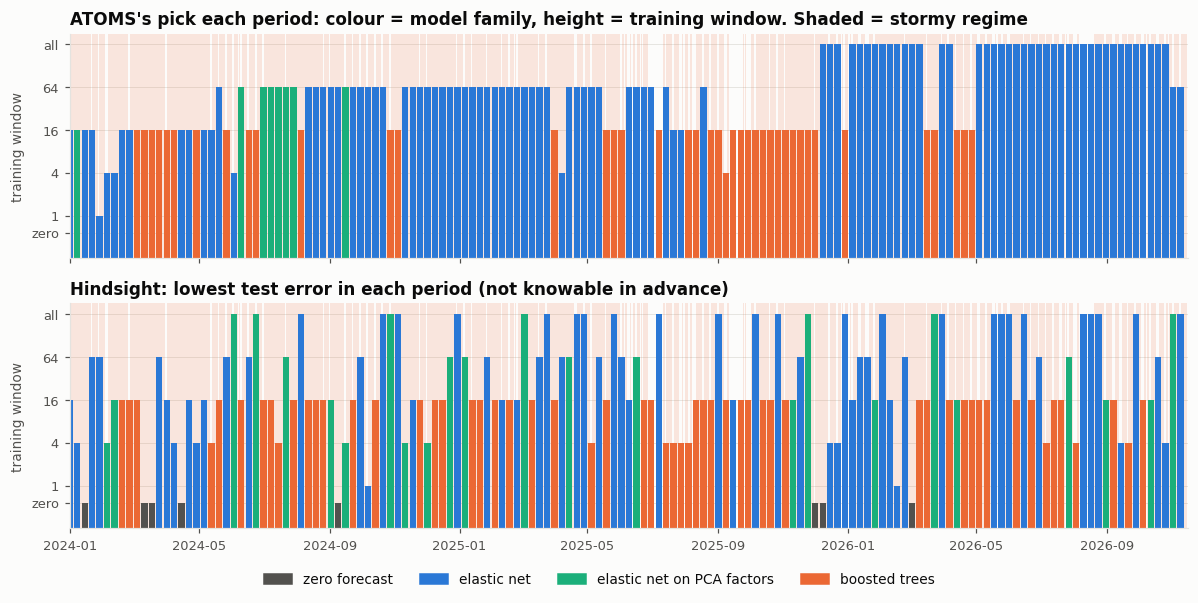

atoms,boosted trees,elastic net,elastic net on PCA factors
row_0,,,
calm,67%,33%,0%
stormy,24%,70%,6%


In [15]:
fam = lambda lab: "zero" if lab == "zero" else ("enet + PCA" if lab.startswith("enet") and "pca" in lab else lab.split("(")[0])
FAM_COLOR = {"zero": plotting.MUTED, "enet": plotting.BLUE, "enet + PCA": plotting.AQUA, "gbt": plotting.ORANGE}
FAM_NAME = {"zero": "zero forecast", "enet": "elastic net", "enet + PCA": "elastic net on PCA factors", "gbt": "boosted trees"}
s = sel.copy(); s.index = pd.PeriodIndex(s.index.astype(str), freq=PERIOD)
s = s[s.index.to_timestamp(how="end") >= REPORT_FROM.tz_localize(None)]
x = s.index.to_timestamp()
win_h = lambda w: {-1: 0.6, 1: 1, 4: 2, 16: 3, 64: 4, 0: 5}.get(int(w), 1)
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, who in zip(axes, ("atoms", "hindsight_best")):
    shade_regimes(ax)
    wcol = "atoms_window" if who == "atoms" else "hindsight_window"
    ax.bar(x, [win_h(w) for w in s[wcol]], width=6, color=[FAM_COLOR[fam(l)] for l in s[who]])
    ax.set_yticks([0.6, 1, 2, 3, 4, 5]); ax.set_yticklabels(["zero", "1", "4", "16", "64", "all"]); ax.set_ylabel("training window")
axes[0].set_title("ATOMS's pick each period: colour = model family, height = training window. Shaded = stormy regime")
axes[1].set_title("Hindsight: lowest test error in each period (not knowable in advance)")
axes[-1].set_xlim(REPORT_FROM.tz_localize(None), x.max() + pd.Timedelta(days=7))
fig.legend(handles=[Patch(color=c, label=FAM_NAME[k]) for k, c in FAM_COLOR.items()], ncol=4, loc="lower center", bbox_to_anchor=(0.5, 0))
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()
stormy_week = regime.groupby(regime.index.tz_convert(None).to_period(PERIOD)).mean().reindex(s.index).fillna(0) > 0.5
ct = pd.crosstab(np.where(stormy_week, "stormy", "calm"), s["atoms"].map(fam).map(FAM_NAME), normalize="index") * 100
display(ct.style.format("{:.0f}%").set_caption("ATOMS's choice of family, by regime (% of weeks)"))

## 7. Is the edge real?

A backtest on 1-minute closes can profit from **bid-ask bounce**: if a minute closes on a trade at the ask, the next close is more likely to be at the bid, so "fade the last move" looks profitable without any real price move behind it.

**Execution delay.** Act on each forecast 1, 2 or 5 minutes late. Bounce is gone within a minute or two; a slower signal decays gradually. If the Sharpe ratio collapses at a one-minute delay, the edge lives entirely inside the next minute. Notebook 05 then checks whether that is bounce or a genuine effect.

In [16]:
pos_sign = sizing.sign_pos(rep["atoms"])
delay_tab = pd.DataFrame({f"{d} min": sizing.perf(sizing.run(pos_sign, rep["ret_fwd"], delay=d), HORIZON) for d in DELAYS}).T
delay_tab[["sharpe_daily", "ann_return_%", "hit_rate_%"]].style.format("{:,.2f}").set_caption("ATOMS v2, sign positions: effect of execution delay")

,sharpe_daily,ann_return_%,hit_rate_%
0 min,6.53,348.70,49.12
1 min,-0.15,-7.27,48.35
2 min,-1.09,-53.41,48.27
5 min,-1.07,-51.06,48.40


## 8. Position sizing

Three ways to turn the same forecast into a position:

| Rule | Size |
|---|---|
| **Sign** (notebook 03) | ±1, always fully invested |
| **Volatility target** | Direction from the forecast; size = target volatility ÷ recent volatility, capped at `LEVERAGE_CAP`. Smaller in stormy markets, larger in calm ones. Uses the thing that *is* forecastable, volatility, to size a bet on the thing that mostly isn't. |
| **Proportional with a no-trade band** | Size grows with the forecast relative to its own typical size; forecasts below `BAND` × typical are ignored. Only useful if the forecast's magnitude means something. |

Plus two benchmarks: the **time-of-day** rule from section 5, and **buy-and-hold**.

**Bigger positions are not better positions.** Doubling every position doubles the return *and* the volatility, so the Sharpe ratio is unchanged; the drawdown grows faster than proportionally because losses compound. So the equity curves are all rescaled to the same annual volatility (`EQUAL_RISK`) before plotting. That rescaling uses the whole sample, so it is for display only; the table shows the unscaled numbers.

,ann_return_%,ann_vol_%,sharpe_daily,max_drawdown_%,hit_rate_%,avg_|position|
"ATOMS, sign",348.70,48.34,6.53,-41.58,49.12,1.00
"ATOMS, vol target",503.60,41.22,10.07,-32.48,49.12,1.25
"ATOMS, proportional + band",296.33,37.72,7.44,-33.01,49.39,0.59
time of day (fixed on 2023),47.14,48.34,0.98,-55.86,48.44,1.00
buy & hold,14.48,48.34,0.31,-57.99,48.42,1.00


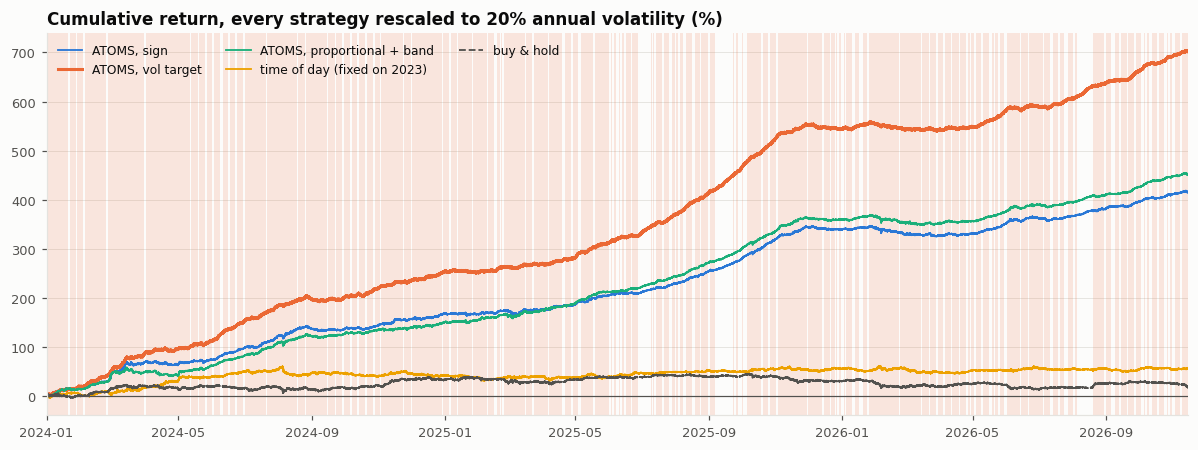

In [17]:
vol_min = F.loc[rep.index, "rv_60"].astype(float) / np.sqrt(60)
hour_sign = np.sign(hp[("mean", "design")])
tod_pos = pd.Series(rep.index.hour.map(hour_sign).to_numpy(dtype=float), index=rep.index)
strategies = {
    "ATOMS, sign": sizing.sign_pos(rep["atoms"]),
    "ATOMS, vol target": sizing.vol_target_pos(rep["atoms"], vol_min, VOL_TARGET, LEVERAGE_CAP),
    "ATOMS, proportional + band": sizing.proportional_pos(rep["atoms"], band=BAND),
    "time of day (fixed on 2023)": tod_pos,
    "buy & hold": pd.Series(1.0, index=rep.index),
}
res = {k: sizing.run(p, rep["ret_fwd"]) for k, p in strategies.items()}
display(pd.DataFrame({k: sizing.perf(r, HORIZON) for k, r in res.items()}).T.style.format("{:,.2f}")
        .set_caption("Unscaled performance"))

fig, ax = plt.subplots(figsize=(11, 4.2)); shade_regimes(ax)
for i, (k, r) in enumerate(res.items()):
    eq = sizing.equal_risk(r["pnl"], EQUAL_RISK).cumsum() * 100
    ax.plot(eq.index, eq, label=k, lw=2 if i == 1 else 1.2, ls="--" if k == "buy & hold" else "-",
            color=[plotting.BLUE, plotting.ORANGE, plotting.AQUA, plotting.YELLOW, plotting.MUTED][i])
ax.axhline(0, color=plotting.MUTED, lw=0.8); ax.legend(ncol=3, loc="upper left", fontsize=8)
ax.set_xlim(REPORT_FROM, rep.index.max())
ax.set_title(f"Cumulative return, every strategy rescaled to {EQUAL_RISK:.0%} annual volatility (%)"); plt.tight_layout(); plt.show()

In [18]:
for d in (0, 1):
    k = sizing.kelly_leverage(sizing.run(sizing.sign_pos(rep["atoms"]), rep["ret_fwd"], delay=d)["pnl"])
    print(f"Kelly leverage implied by the sign strategy with a {d}-minute delay: {k:,.1f}x")

Kelly leverage implied by the sign strategy with a 0-minute delay: 14.9x
Kelly leverage implied by the sign strategy with a 1-minute delay: -0.3x


**Reading the Kelly numbers.** Kelly leverage, μ/σ², is the leverage that maximises long-run growth *if μ is known*. A large number at zero delay that collapses at a one-minute delay says the edge estimate, not the risk, is the problem. Kelly is only as good as the edge it is fed, and over-betting an overestimated edge is the classic way strategies blow up. That is why sizing here targets volatility rather than leverage.

## 9. Summary

Results of the real run (report period from 2024-01-01, seed 0, 64 features, 27 candidates):

- **Regimes:** after removing the daily cycle, the stormy state covers 74.5% of hours with typical stays of 2.9 days (70 hours; calm stays 1.8 days), vs 52.2% and 8.5 hours before. Stays are now days instead of hours, but the stormy state is the majority, so it behaves more like "normal vs unusually calm" than a rare storm.
- **Features:** 31 of 63 features pass the Bonferroni bar (|t| > 3.36) on 2023 (`weekend` is constant within a day, so it is untestable here); the strongest groups are momentum (11 pass) and location (5), then order flow (5), regime (5) and scaled returns (4). The signs are negative, i.e. short-horizon reversal. 18 of 2,016 feature pairs are correlated above 0.8.
- **PCA:** 38 components explain 95% of feature variance (29 for 90%); the most predictive component is PC6 (|t| = 16.0), not PC1 or PC2, i.e. high variance does not mean signal.
- **Time of day:** design-vs-after correlation of hourly returns is +0.18, so direction is not reliably predictable by hour. A fixed time-of-day rule earns a Sharpe of only 0.98.
- **Accuracy:** ATOMS v2 OOS R² is -0.0317% vs -0.0140% for the baseline. Diebold-Mariano: v2 vs baseline p = 0.170 (no improvement), v2 vs best fixed candidate (+0.0074%, elastic net, all history) p = 0.016 (v2 is significantly worse), v2 vs zero forecast p = 0.051. The extended features did not improve the forecast, and ATOMS did not recover the best fixed choice.
- **Execution delay:** the sign strategy's Sharpe is 6.53 at zero delay, -0.15 at one minute and -1.09 at two minutes. A leakage audit (below) found no look-ahead: deleting all data after a test week leaves that week's forecasts bit-identical, and entering at the *first* trade of the next minute instead of the last print of this one keeps the Sharpe at 6.52, so this is not last-print bid-ask bounce either. On the raw 1-second data the P&L accrues gradually through the next minute and is gone by its end: a real but tiny flow-persistence effect, about 0.07 bp per minute against a per-minute volatility of about 6 bp (R² of 0.01%), which becomes a large Sharpe because it is harvested 1,440 times a day (information ratio per trade 0.0099 × √(1,440 × 365) ≈ 7). Implied Kelly leverage falls from 14.9x to -0.3x with a one-minute delay.
- **Sizing:** volatility targeting changes the Sharpe from 6.53 to 10.07 and the max drawdown from -41.6% to -32.5%; proportional sizing with a no-trade band gives 7.44 and -33.0%. Buy-and-hold is 0.31. All of these are zero-delay figures; with a one-minute delay the edge is gone.

### Leakage audit

Checks run on the cached results after the run (code in `scripts/leakage_audit.py`, numbers from seed 0, report period 2024-01-01 onward):

| Check | Result |
|---|---|
| 1-second bars indexed by open time; 1-minute close = last 1-second close, open = first open, high/low match | Yes, exact |
| Cached target `y` equals 1e4 × (log close[i+1] − log close[i]) recomputed from the 1-minute bars | Yes, max difference 0 |
| Every test row's period label matches its timestamp's week; no duplicate timestamps | Yes |
| Rebuild features with all data after a cut-off deleted (section 2) | No feature value changes |
| Rebuild regimes, features, split and every candidate fit for one test week with every later bar deleted, compare with the cached forecasts | Identical (max difference 3e-7, float32 rounding) |
| P&L from close(i) to the first trade of minute i+1 (the part a last-print bounce would deliver) | 0.1% of total P&L, Sharpe 1.3 |
| P&L from the first trade of minute i+1 to its close (an entry you could actually get) | Sharpe 6.52, i.e. all of it |
| Inside minute i+1 on raw 1-second data, where the P&L accrues | Gradually across the minute, not at the boundary; varies by month (Sharpe 22 in 2024-06, 1.9 in 2025-03) |
| Forecast magnitude vs realised P&L | Monotonic across |forecast| quintiles (−0.005 to +0.139 bp) |
| Vol-targeted Sharpe with the volatility estimate lagged 1 and 60 minutes | 10.07 → 10.09 → 8.79 |
| Block-permutation test: shuffle the forecast series in week-long blocks and rebuild the backtest, 500 times | Null Sharpe 0.00 ± 0.57, max 1.52; the real 6.53 is 11.5 sd above the null, p < 0.002 |

Two minor, unexploitable points: rows whose next minute is missing are dropped (so the sample excludes minutes just before a gap), and the HMM and the hour-of-day deseasonalisation are estimated in-sample on 2023, which is training data for later weeks but never test data.
